<a href="https://colab.research.google.com/github/manikanta-eng/python-project/blob/main/brain_tumor_mri.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TF: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


100%|██████████| 157M/157M [00:09<00:00, 17.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2
Train dir: /root/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Training
Test dir : /root/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2/Testing
Total images : 7200
Training     : 5600   Testing: 1600
Classes (4): ['glioma', 'meningioma', 'notumor', 'pituitary']


,Training,Testing,Total
glioma,1400,400,1800
meningioma,1400,400,1800
notumor,1400,400,1800
pituitary,1400,400,1800


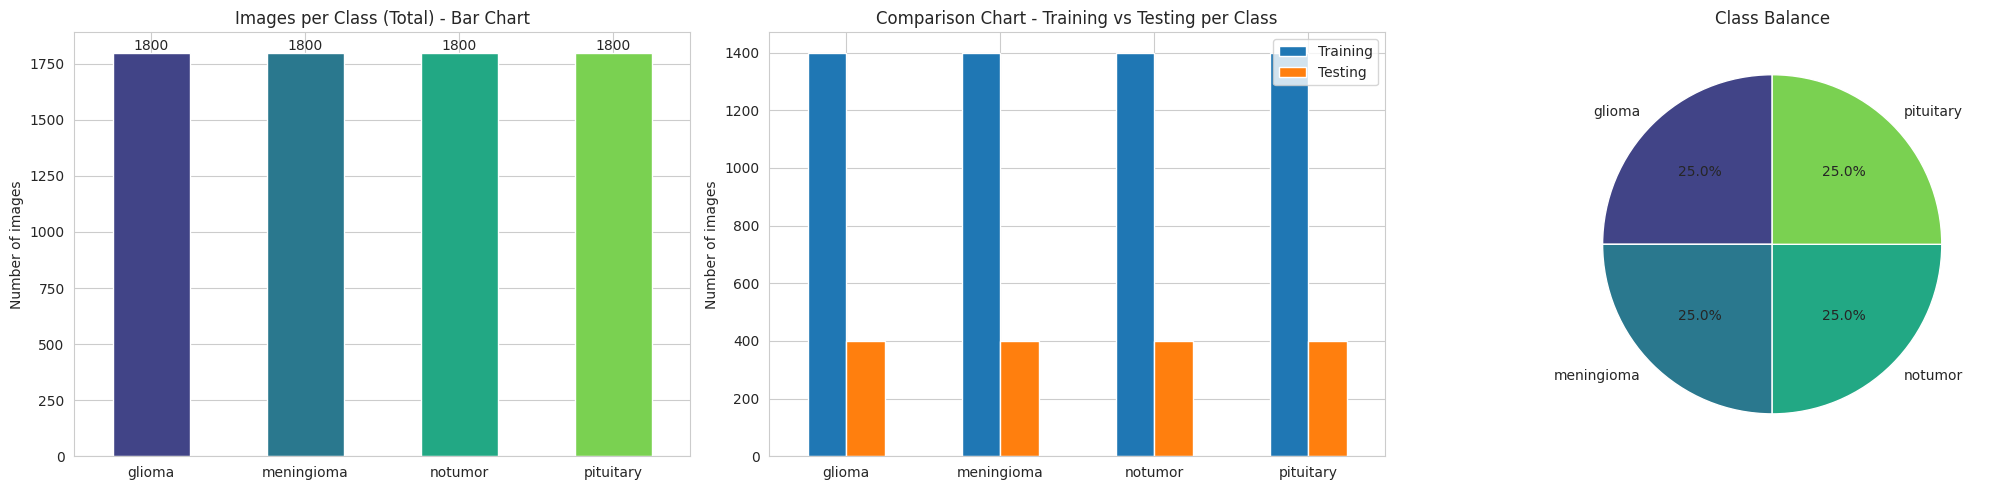

Imbalance ratio (largest / smallest class): 1.00


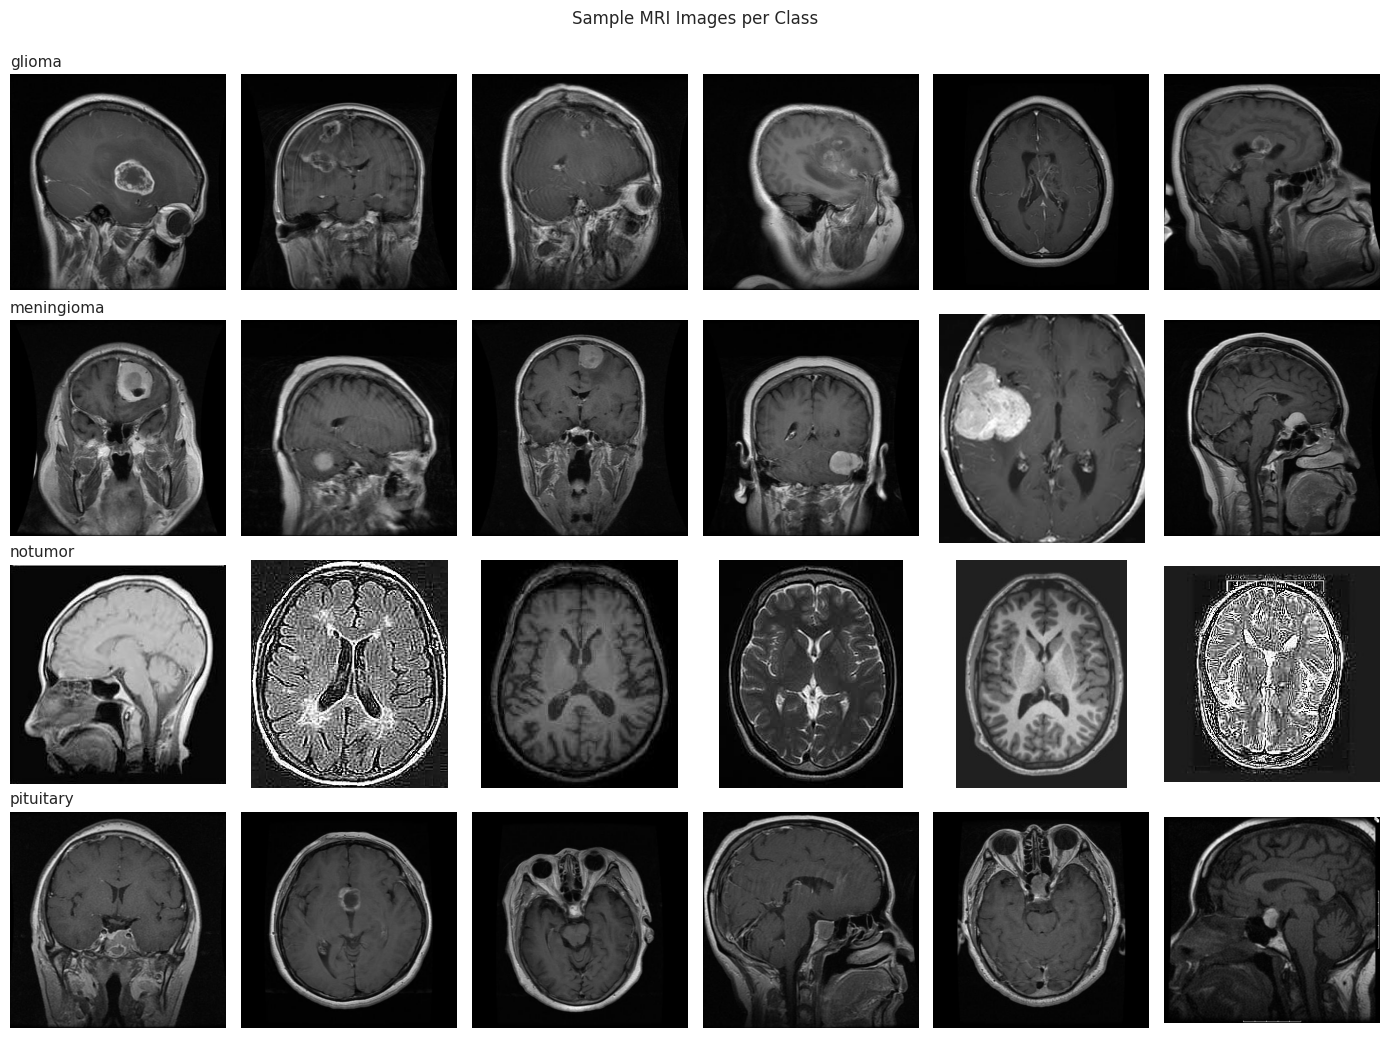

Unique image sizes: 447
width  height
512    512       5014
225    225        338
630    630         90
201    251         57
228    221         51
232    217         50
236    236         48
442    442         48
dtype: int64
Colour modes: {'RGB': 4129, 'L': 3067, 'RGBA': 3, 'P': 1}


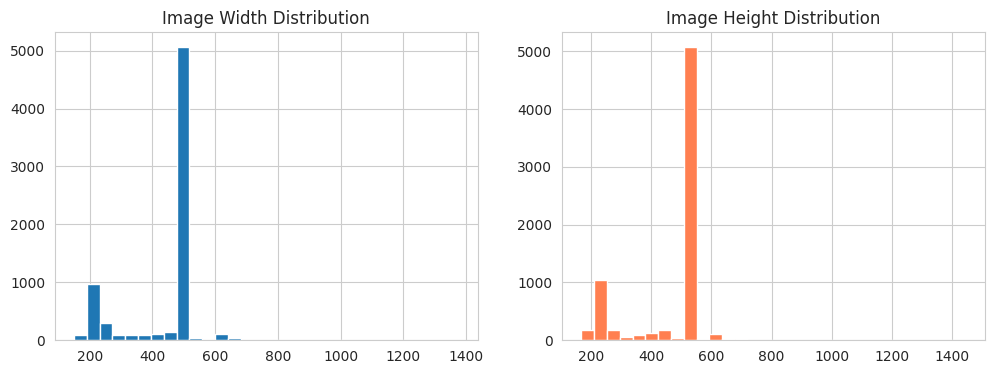

Total images                          : 7200
Duplicate copies (extra files)        : 187
Files involved in duplication         : 340
Train/Test overlap (data leakage)     : 0
Duplicates per class:
class
glioma         14
meningioma     16
notumor       119
pituitary      38
dtype: int64
Same image under different classes    : 0


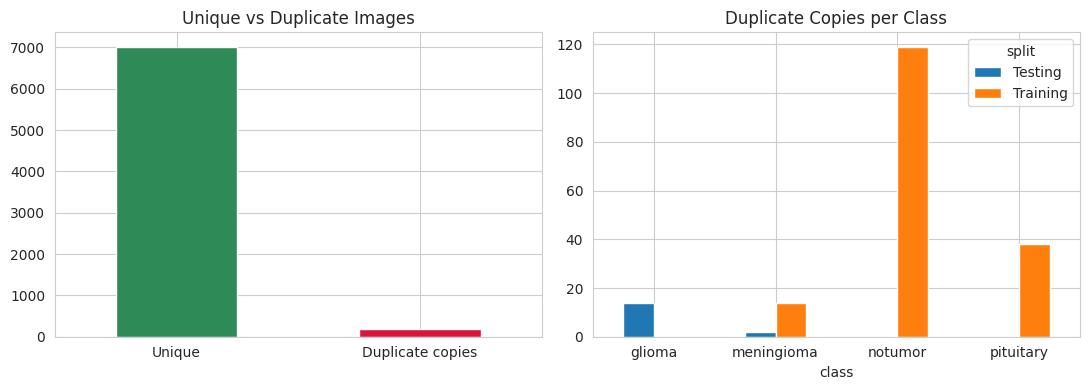

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
Train 4480 | Validation 1120 | Test 1600


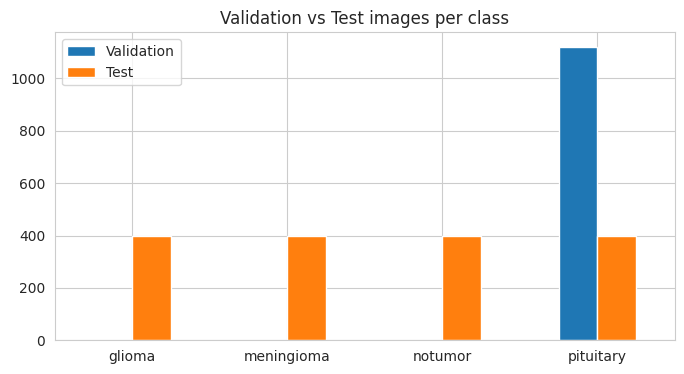


Training VGG16
Epoch 1/3
140/140 - 36s - 258ms/step - accuracy: 0.5074 - loss: 2.1815 - val_accuracy: 0.8045 - val_loss: 0.5023 - lr: 0.0010 - learning_rate: 0.0010
Epoch 2/3
140/140 - 25s - 179ms/step - accuracy: 0.7100 - loss: 0.9799 - val_accuracy: 0.7973 - val_loss: 0.4934 - lr: 0.0010 - learning_rate: 0.0010
Epoch 3/3
140/140 - 26s - 186ms/step - accuracy: 0.7752 - loss: 0.6877 - val_accuracy: 0.9375 - val_loss: 0.1718 - lr: 0.0010 - learning_rate: 0.0010
Epoch 1/5
140/140 - 94s - 674ms/step - accuracy: 0.8400 - loss: 0.4405 - val_accuracy: 0.9786 - val_loss: 0.0805 - lr: 1.0000e-05 - learning_rate: 1.0000e-05
Epoch 2/5
140/140 - 73s - 520ms/step - accuracy: 0.8991 - loss: 0.2718 - val_accuracy: 0.9911 - val_loss: 0.0377 - lr: 1.0000e-05 - learning_rate: 1.0000e-05
Epoch 3/5
140/140 - 73s - 521ms/step - accuracy: 0.9371 - loss: 0.1781 - val_accuracy: 0.9920 - val_loss: 0.0236 - lr: 1.0000e-05 - learning_rate: 1.0000e-05
Epoch 4/5
140/140 - 73s - 520ms/step - accuracy: 0.9489 - lo

,Model,Params (M),Best Train Acc,Final Val Acc,Final Val Loss,Test Acc,Test Loss,Train Time (min)
0,VGG16,14.720000,0.9690,1.0000,0.0024,0.9131,0.6080,7.900000
1,Xception,20.870000,0.9364,0.9902,0.0510,0.8969,0.3426,11.800000
2,ResNet50,23.600000,0.9571,0.9893,0.0335,0.8931,0.4587,8.900000
3,InceptionV3,21.810000,0.9190,0.9777,0.0929,0.8900,0.3299,6.800000
4,DenseNet121,7.040000,0.9286,0.9902,0.0395,0.8863,0.4218,12.600000
5,MobileNetV2,2.260000,0.8808,0.9393,0.2148,0.8112,0.6497,4.000000
6,EfficientNetB0,4.050000,0.8618,0.9232,0.3728,0.8031,0.5719,5.100000


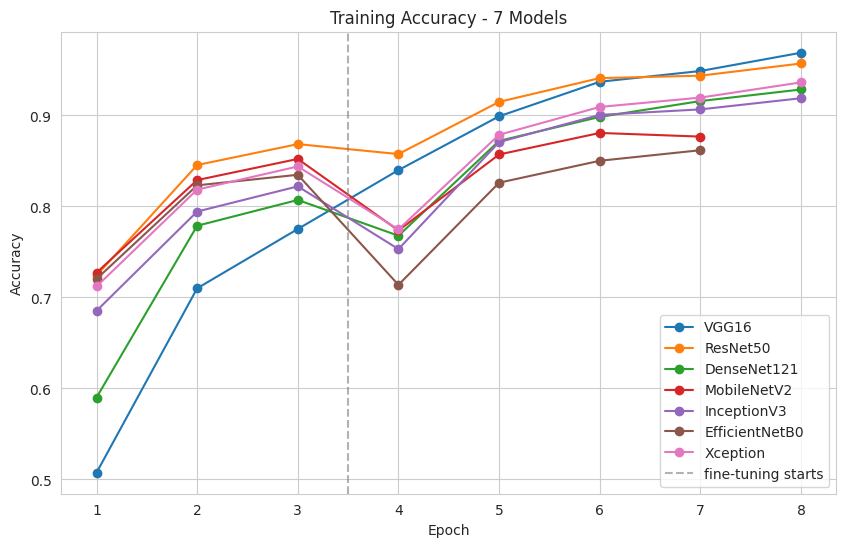

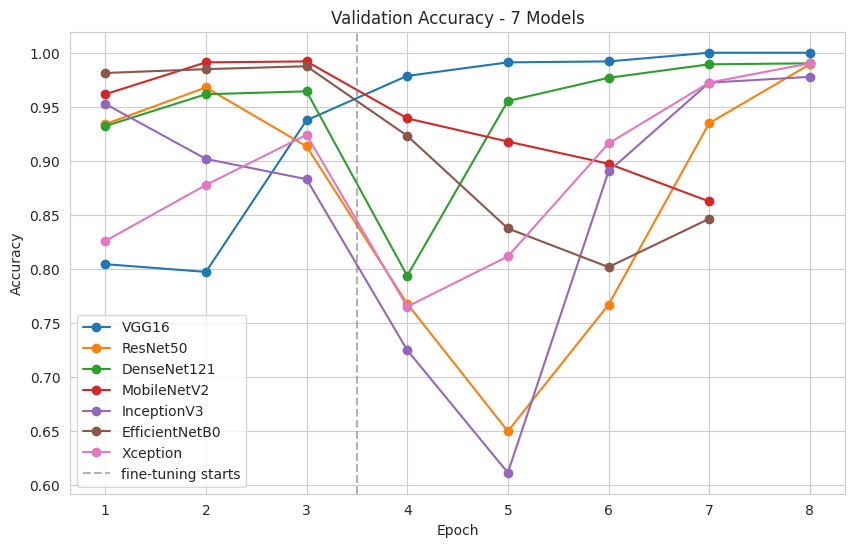

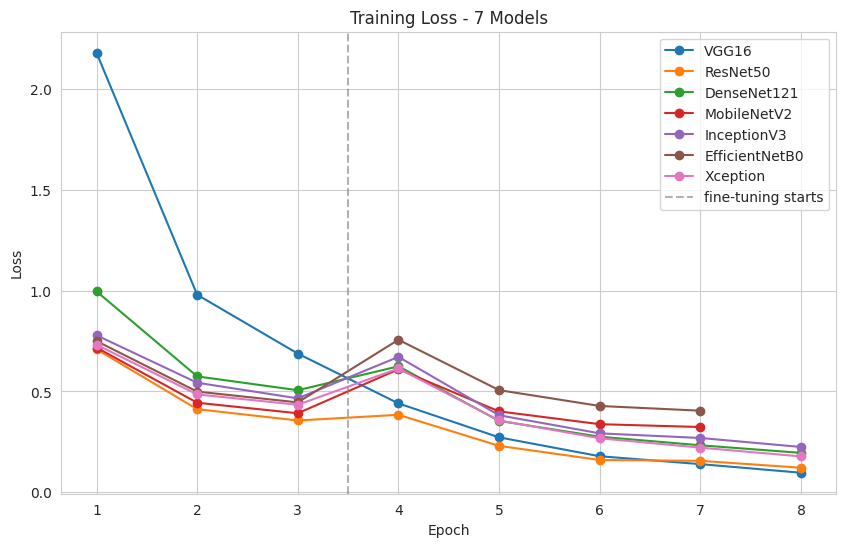

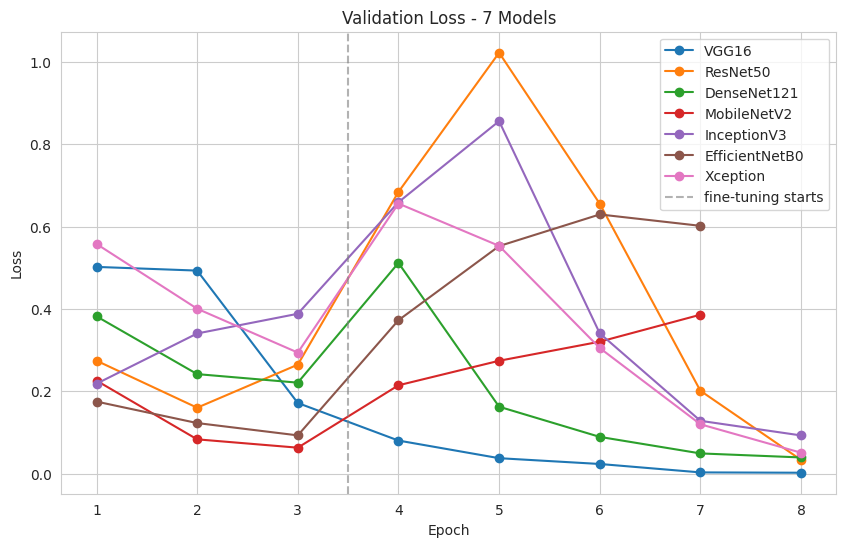

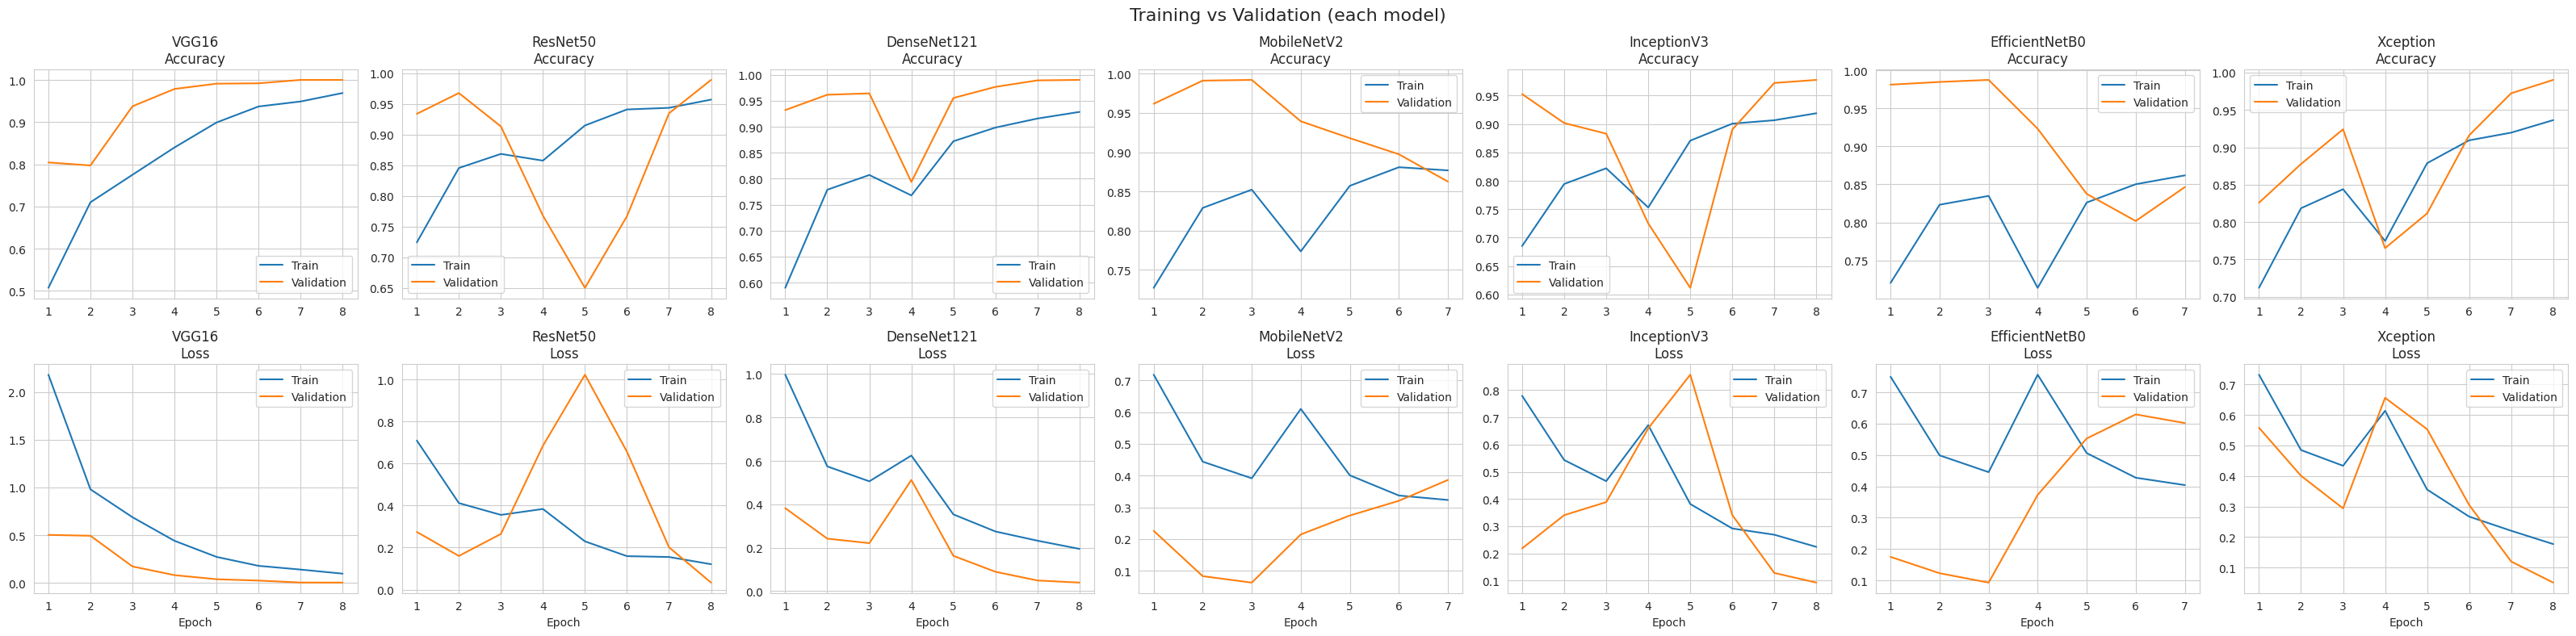

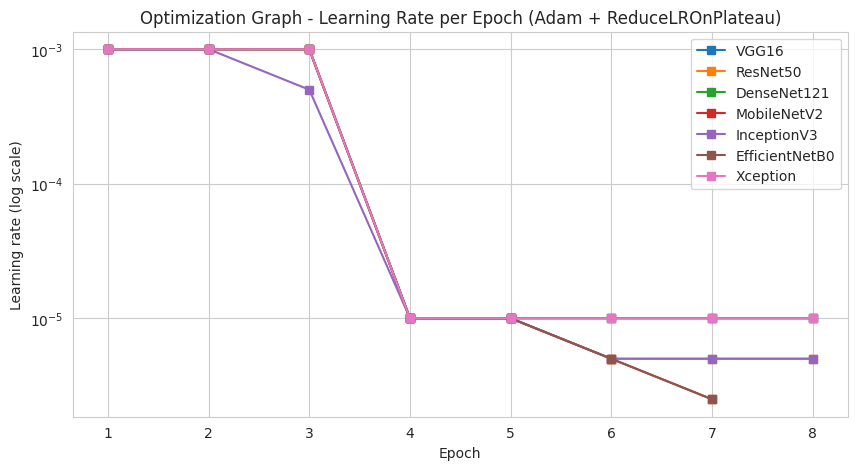

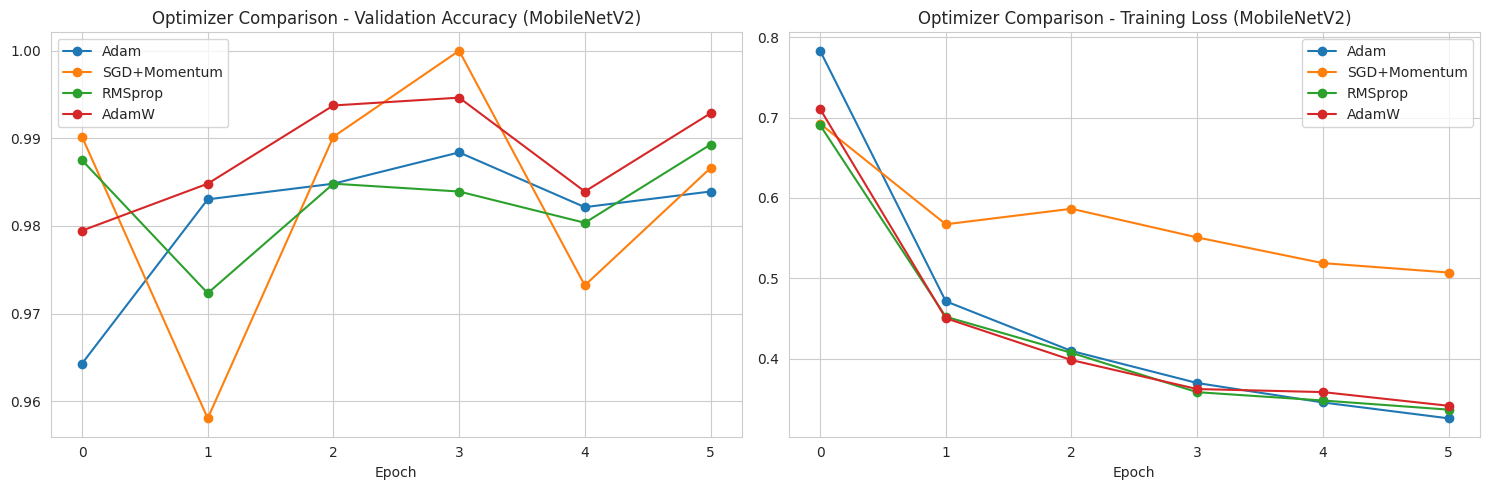

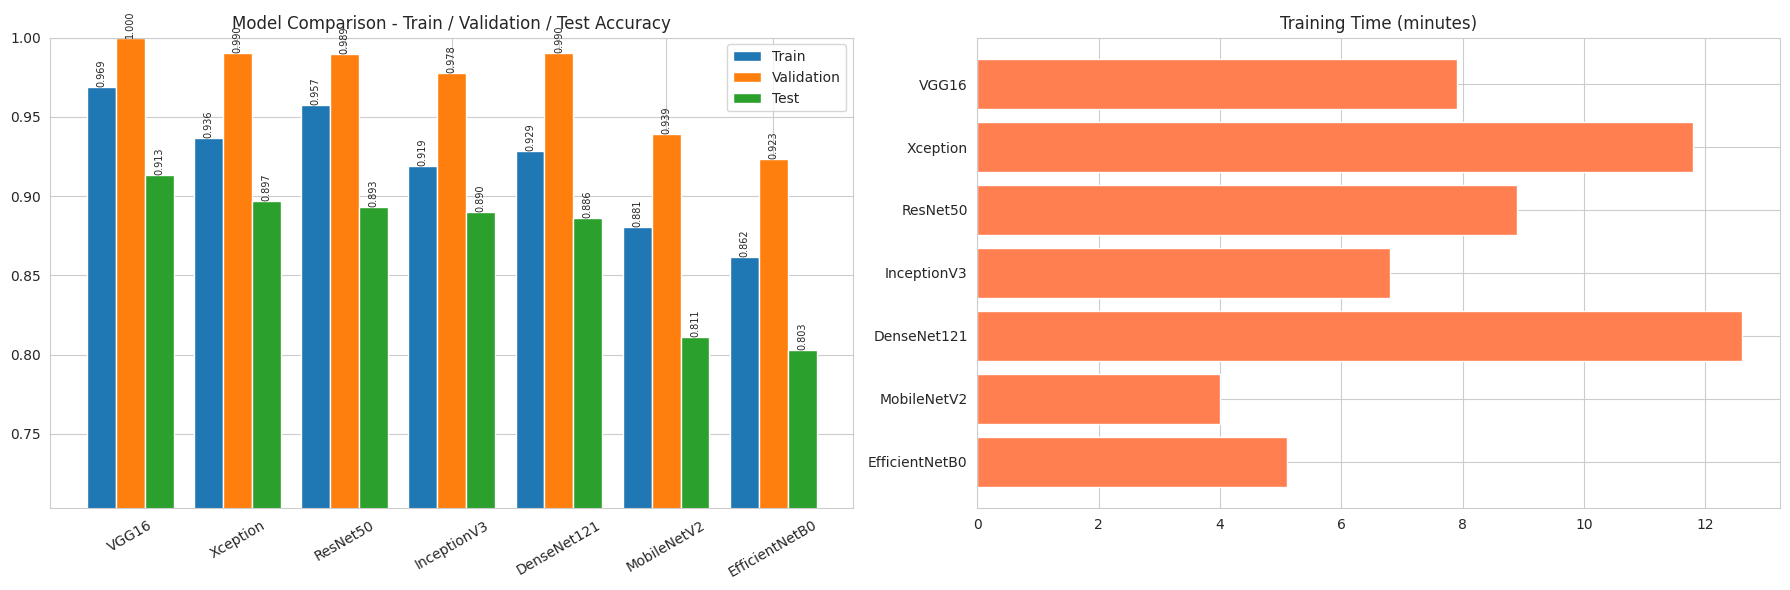

Best model: VGG16

              precision    recall  f1-score   support

      glioma     0.9673    0.8125    0.8832       400
  meningioma     0.8966    0.8450    0.8700       400
     notumor     0.9172    0.9975    0.9557       400
   pituitary     0.8827    0.9975    0.9366       400

    accuracy                         0.9131      1600
   macro avg     0.9159    0.9131    0.9114      1600
weighted avg     0.9159    0.9131    0.9114      1600



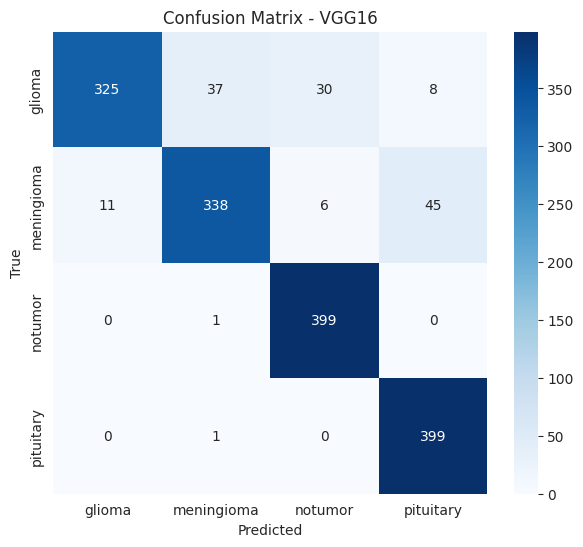

Saved model_comparison.csv and histories.json


In [3]:
# %% [markdown]
# # Brain Tumor MRI Classification - 7 Deep Learning Models (Google Colab)
# Dataset: Brain Tumor MRI Dataset (masoudnickparvar) - glioma, meningioma, pituitary, no tumor (~7,000 images).
# Runtime -> Change runtime type -> **T4 GPU** before running.

# %% Install & imports
!pip -q install kagglehub

import os, hashlib, time, warnings, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.applications import (VGG16, ResNet50, DenseNet121, MobileNetV2,
                                           InceptionV3, EfficientNetB0, Xception)
from tensorflow.keras.applications import (vgg16, resnet50, densenet, mobilenet_v2,
                                           inception_v3, efficientnet, xception)
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("TF:", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

# %% Config
IMG = 224            # image size
BATCH = 32
HEAD_EPOCHS = 3      # phase 1: train classifier head (base frozen)
FT_EPOCHS = 5        # phase 2: fine-tune whole network
VAL_SPLIT = 0.2      # part of Training folder used for validation
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# %% [markdown]
# ## 1. Initial Analysis

# %% Download dataset (kagglehub)
try:
    path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
except Exception as e:
    print("Download needs Kaggle login ->", e)
    kagglehub.login()          # paste your Kaggle username + API token when asked
    path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Path to dataset files:", path)

# locate the Training / Testing folders wherever they are
TRAIN_DIR = TEST_DIR = None
for root, dirs, _ in os.walk(path):
    if "Training" in dirs and "Testing" in dirs:
        TRAIN_DIR, TEST_DIR = os.path.join(root, "Training"), os.path.join(root, "Testing")
        break
assert TRAIN_DIR, "Training/Testing folders not found"
print("Train dir:", TRAIN_DIR); print("Test dir :", TEST_DIR)

# %% Count images per class
class_names = sorted(d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d)))
NUM_CLASSES = len(class_names)
EXT = (".jpg", ".jpeg", ".png")

def list_files(folder):
    return {c: [os.path.join(folder, c, f) for f in sorted(os.listdir(os.path.join(folder, c))) if f.lower().endswith(EXT)]
            for c in class_names}

train_files, test_files = list_files(TRAIN_DIR), list_files(TEST_DIR)
dist = pd.DataFrame({"Training": {c: len(v) for c, v in train_files.items()},
                     "Testing":  {c: len(v) for c, v in test_files.items()}})
dist["Total"] = dist.sum(axis=1)
total = int(dist["Total"].sum())
print(f"Total images : {total}")
print(f"Training     : {dist['Training'].sum()}   Testing: {dist['Testing'].sum()}")
print(f"Classes ({NUM_CLASSES}): {class_names}")
display(dist)

# %% Bar chart + comparison chart + pie chart
fig, ax = plt.subplots(1, 3, figsize=(21, 5))
dist["Total"].plot(kind="bar", ax=ax[0], color=sns.color_palette("viridis", NUM_CLASSES))
ax[0].set_title("Images per Class (Total) - Bar Chart"); ax[0].set_ylabel("Number of images")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax[0].tick_params(axis="x", rotation=0)

dist[["Training", "Testing"]].plot(kind="bar", ax=ax[1])
ax[1].set_title("Comparison Chart - Training vs Testing per Class"); ax[1].set_ylabel("Number of images")
ax[1].tick_params(axis="x", rotation=0)

ax[2].pie(dist["Total"], labels=class_names, autopct="%1.1f%%", startangle=90,
          colors=sns.color_palette("viridis", NUM_CLASSES))
ax[2].set_title("Class Balance")
plt.tight_layout(); plt.show()

imb = dist["Total"].max() / dist["Total"].min()
print(f"Imbalance ratio (largest / smallest class): {imb:.2f}")

# %% Sample images
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(14, 2.6 * NUM_CLASSES))
for r, c in enumerate(class_names):
    for j, f in enumerate(random.sample(train_files[c], 6)):
        axes[r, j].imshow(Image.open(f).convert("RGB")); axes[r, j].axis("off")
    axes[r, 0].set_title(c, loc="left", fontsize=11)
plt.suptitle("Sample MRI Images per Class", y=1.0); plt.tight_layout(); plt.show()

# %% Image size analysis
rows = []
for split, files in [("Training", train_files), ("Testing", test_files)]:
    for c, fl in files.items():
        for f in fl:
            with Image.open(f) as im:
                rows.append((split, c, im.size[0], im.size[1], im.mode))
meta = pd.DataFrame(rows, columns=["split", "class", "width", "height", "mode"])
print("Unique image sizes:", meta.groupby(["width", "height"]).ngroups)
print(meta.groupby(["width", "height"]).size().sort_values(ascending=False).head(8))
print("Colour modes:", meta["mode"].value_counts().to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(meta["width"], bins=30); ax[0].set_title("Image Width Distribution")
ax[1].hist(meta["height"], bins=30, color="coral"); ax[1].set_title("Image Height Distribution")
plt.show()

# %% Duplicate image analysis (exact duplicates by file hash)
def md5(path):
    with open(path, "rb") as fh:
        return hashlib.md5(fh.read()).hexdigest()

recs = [(split, c, f, md5(f)) for split, files in [("Training", train_files), ("Testing", test_files)]
        for c, fl in files.items() for f in fl]
dup_df = pd.DataFrame(recs, columns=["split", "class", "path", "hash"])
dup_mask = dup_df.duplicated("hash", keep=False)
n_dup_extra = int(dup_df.duplicated("hash").sum())
print(f"Total images                          : {len(dup_df)}")
print(f"Duplicate copies (extra files)        : {n_dup_extra}")
print(f"Files involved in duplication         : {int(dup_mask.sum())}")
h_tr = set(dup_df[dup_df.split == "Training"]["hash"]); h_te = set(dup_df[dup_df.split == "Testing"]["hash"])
print(f"Train/Test overlap (data leakage)     : {len(h_tr & h_te)}")
print("Duplicates per class:")
print(dup_df[dup_df.duplicated("hash")].groupby("class").size())
# label conflicts: same image under different classes
conf = dup_df.groupby("hash")["class"].nunique()
print(f"Same image under different classes    : {int((conf > 1).sum())}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
pd.Series({"Unique": len(dup_df) - n_dup_extra, "Duplicate copies": n_dup_extra}).plot(kind="bar", ax=ax[0], color=["seagreen", "crimson"])
ax[0].set_title("Unique vs Duplicate Images"); ax[0].tick_params(axis="x", rotation=0)
dup_df[dup_df.duplicated("hash")].groupby(["class", "split"]).size().unstack(fill_value=0).plot(kind="bar", ax=ax[1])
ax[1].set_title("Duplicate Copies per Class"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

# optional: drop exact duplicates inside Training so they cannot leak into the validation split
REMOVE_TRAIN_DUPLICATES = False
if REMOVE_TRAIN_DUPLICATES:
    tr_df = dup_df[dup_df.split == "Training"].drop_duplicates("hash")
    train_files = {c: tr_df[tr_df["class"] == c]["path"].tolist() for c in class_names}
    print("Training images after de-duplication:", sum(len(v) for v in train_files.values()))

# %% [markdown]
# ## 2. Data pipeline & 7 models

# %% tf.data datasets
AUTOTUNE = tf.data.AUTOTUNE
common = dict(image_size=(IMG, IMG), batch_size=BATCH, label_mode="int", class_names=class_names)
train_ds = tf.keras.utils.image_dataset_from_directory(TRAIN_DIR, validation_split=VAL_SPLIT, subset="training",
                                                       seed=SEED, shuffle=True, **common)
val_ds   = tf.keras.utils.image_dataset_from_directory(TRAIN_DIR, validation_split=VAL_SPLIT, subset="validation",
                                                       seed=SEED, shuffle=False, **common)
test_ds  = tf.keras.utils.image_dataset_from_directory(TEST_DIR, shuffle=False, **common)

y_val  = np.concatenate([y.numpy() for _, y in val_ds])
y_test = np.concatenate([y.numpy() for _, y in test_ds])
n_train = int(dist["Training"].sum()) - len(y_val)
print(f"Train {n_train} | Validation {len(y_val)} | Test {len(y_test)}")

split_df = pd.DataFrame({"Validation": np.bincount(y_val, minlength=NUM_CLASSES),
                         "Test": np.bincount(y_test, minlength=NUM_CLASSES)}, index=class_names)
split_df.plot(kind="bar", figsize=(8, 4), title="Validation vs Test images per class")
plt.xticks(rotation=0); plt.show()

train_ds = train_ds.prefetch(AUTOTUNE); val_ds = val_ds.prefetch(AUTOTUNE); test_ds = test_ds.prefetch(AUTOTUNE)

# %% Model builders
MODEL_ZOO = {
    "VGG16":          (VGG16,          vgg16.preprocess_input),
    "ResNet50":       (ResNet50,       resnet50.preprocess_input),
    "DenseNet121":    (DenseNet121,    densenet.preprocess_input),
    "MobileNetV2":    (MobileNetV2,    mobilenet_v2.preprocess_input),
    "InceptionV3":    (InceptionV3,    inception_v3.preprocess_input),
    "EfficientNetB0": (EfficientNetB0, efficientnet.preprocess_input),
    "Xception":       (Xception,       xception.preprocess_input),
}

augment = tf.keras.Sequential([layers.RandomFlip("horizontal"),
                               layers.RandomRotation(0.08),
                               layers.RandomZoom(0.1)], name="augment")

def build_model(name):
    base_fn, prep = MODEL_ZOO[name]
    base = base_fn(include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
    base.trainable = False
    inp = layers.Input((IMG, IMG, 3))
    x = augment(inp)
    x = layers.Lambda(prep, name="preprocess")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name=name), base

class LRLogger(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs["lr"] = float(np.array(self.model.optimizer.learning_rate))

def make_cbs():
    return [LRLogger(),
            callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, verbose=0),
            callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]

def train_model(name):
    tf.keras.backend.clear_session()
    model, base = build_model(name)
    t0 = time.time()
    model.compile(optimizer=optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, callbacks=make_cbs(), verbose=2)
    base.trainable = True
    model.compile(optimizer=optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS, callbacks=make_cbs(), verbose=2)
    hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
    return model, hist, time.time() - t0

# %% [markdown]
# ## 3. Train all 7 models (about 40-70 min on a T4 GPU)

# %% Run all models
histories, results, preds = {}, [], {}
for name in MODEL_ZOO:
    print(f"\n{'=' * 70}\nTraining {name}\n{'=' * 70}")
    model, hist, tt = train_model(name)
    histories[name] = hist
    v_loss, v_acc = model.evaluate(val_ds, verbose=0)
    t_loss, t_acc = model.evaluate(test_ds, verbose=0)
    preds[name] = model.predict(test_ds, verbose=0)
    results.append({"Model": name,
                    "Params (M)": round(model.count_params() / 1e6, 2),
                    "Best Train Acc": max(hist["accuracy"]),
                    "Final Val Acc": v_acc, "Final Val Loss": v_loss,
                    "Test Acc": t_acc, "Test Loss": t_loss,
                    "Train Time (min)": round(tt / 60, 1)})
    print(f"{name}: val acc = {v_acc:.4f} | test acc = {t_acc:.4f} | test loss = {t_loss:.4f}")
    del model

res_df = pd.DataFrame(results).sort_values("Test Acc", ascending=False).reset_index(drop=True)
display(res_df.style.format({c: "{:.4f}" for c in ["Best Train Acc", "Final Val Acc", "Final Val Loss", "Test Acc", "Test Loss"]})
        .background_gradient(cmap="Greens", subset=["Test Acc", "Final Val Acc"]))

# %% [markdown]
# ## 4. Graphs

# %% Accuracy / validation / loss graphs for all 7 models
colors = sns.color_palette("tab10", len(histories))
def plot_metric(key, title, ylabel):
    plt.figure(figsize=(10, 6))
    for (n, h), c in zip(histories.items(), colors):
        plt.plot(range(1, len(h[key]) + 1), h[key], marker="o", label=n, color=c)
    plt.axvline(HEAD_EPOCHS + 0.5, color="gray", ls="--", alpha=.6, label="fine-tuning starts")
    plt.title(title); plt.xlabel("Epoch"); plt.ylabel(ylabel); plt.legend(); plt.grid(True); plt.show()

plot_metric("accuracy",     "Training Accuracy - 7 Models",   "Accuracy")
plot_metric("val_accuracy", "Validation Accuracy - 7 Models", "Accuracy")
plot_metric("loss",         "Training Loss - 7 Models",       "Loss")
plot_metric("val_loss",     "Validation Loss - 7 Models",     "Loss")

# %% Training vs Validation graph for each model
fig, axes = plt.subplots(2, 7, figsize=(32, 8))
for i, (n, h) in enumerate(histories.items()):
    ep = range(1, len(h["accuracy"]) + 1)
    axes[0, i].plot(ep, h["accuracy"], label="Train"); axes[0, i].plot(ep, h["val_accuracy"], label="Validation")
    axes[0, i].set_title(f"{n}\nAccuracy"); axes[0, i].legend(); axes[0, i].grid(True)
    axes[1, i].plot(ep, h["loss"], label="Train"); axes[1, i].plot(ep, h["val_loss"], label="Validation")
    axes[1, i].set_title(f"{n}\nLoss"); axes[1, i].set_xlabel("Epoch"); axes[1, i].legend(); axes[1, i].grid(True)
plt.suptitle("Training vs Validation (each model)", fontsize=16); plt.tight_layout(); plt.show()

# %% Optimization graph: learning rate per epoch
plt.figure(figsize=(10, 5))
for (n, h), c in zip(histories.items(), colors):
    plt.plot(range(1, len(h["lr"]) + 1), h["lr"], marker="s", label=n, color=c)
plt.yscale("log"); plt.title("Optimization Graph - Learning Rate per Epoch (Adam + ReduceLROnPlateau)")
plt.xlabel("Epoch"); plt.ylabel("Learning rate (log scale)"); plt.legend(); plt.grid(True); plt.show()

# %% Optimizer comparison (Adam / SGD / RMSprop / AdamW) on MobileNetV2
def quick_opt_run(opt_name, epochs=6):
    tf.keras.backend.clear_session()
    model, _ = build_model("MobileNetV2")
    opts = {"Adam": optimizers.Adam(1e-3),
            "SGD+Momentum": optimizers.SGD(1e-2, momentum=0.9),
            "RMSprop": optimizers.RMSprop(1e-3),
            "AdamW": optimizers.AdamW(1e-3)}
    model.compile(optimizer=opts[opt_name], loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0).history

opt_hist = {o: quick_opt_run(o) for o in ["Adam", "SGD+Momentum", "RMSprop", "AdamW"]}
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for o, h in opt_hist.items():
    ax[0].plot(h["val_accuracy"], marker="o", label=o); ax[1].plot(h["loss"], marker="o", label=o)
ax[0].set_title("Optimizer Comparison - Validation Accuracy (MobileNetV2)"); ax[0].set_xlabel("Epoch"); ax[0].legend(); ax[0].grid(True)
ax[1].set_title("Optimizer Comparison - Training Loss (MobileNetV2)");       ax[1].set_xlabel("Epoch"); ax[1].legend(); ax[1].grid(True)
plt.tight_layout(); plt.show()

# %% Seven-model validation / test comparison
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
x = np.arange(len(res_df)); w = 0.27
ax[0].bar(x - w, res_df["Best Train Acc"], w, label="Train")
ax[0].bar(x,     res_df["Final Val Acc"],  w, label="Validation")
ax[0].bar(x + w, res_df["Test Acc"],       w, label="Test")
ax[0].set_xticks(x); ax[0].set_xticklabels(res_df["Model"], rotation=30)
ax[0].set_ylim(max(0, res_df[["Final Val Acc", "Test Acc"]].min().min() - 0.1), 1.0)
ax[0].set_title("Model Comparison - Train / Validation / Test Accuracy"); ax[0].legend()
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=7, rotation=90)
ax[1].barh(res_df["Model"], res_df["Train Time (min)"], color="coral")
ax[1].set_title("Training Time (minutes)"); ax[1].invert_yaxis()
plt.tight_layout(); plt.show()

# %% Confusion matrix + classification report (best model)
best = res_df.loc[0, "Model"]
y_pred = preds[best].argmax(1)
print(f"Best model: {best}\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix - {best}"); plt.xlabel("Predicted"); plt.ylabel("True"); plt.show()

# %% Save results
res_df.to_csv("model_comparison.csv", index=False)
pd.DataFrame({n: pd.Series({k: v for k, v in h.items()}) for n, h in histories.items()}).to_json("histories.json")
print("Saved model_comparison.csv and histories.json")